# Callibration of Neural SDEs

### Goal of the Notebook
Callibrating and learning a Neural SDE
        $$ dX_t=\mu_\theta(t,X_t)dt+\sigma_\theta(t,X_t)dW_t, $$
for parameter space $\Theta \in \mathbb{R}^p$.

The theoretical part on all of the following has been done in Chapter 4 of my Thesis.

We will not use a system of neural SDEs to keep this Notebook simple, however it can be expand it to more dimensions as well.


### Imports and Parameters

In [64]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader

Here we will define the most important parameters we will later need for the calibration. The different parameters will be used for the neural network itself, its training and its simulation.

In [34]:
# ReLu activation function definition
def ReLU(x):
    return np.maximum(0, x)

In [50]:
# size of neural network
hidden_dim = 32 # number of units per layer
layer_num = 2  # number of hidden layers
activation = 'ReLu' # activation function

# training
learning_rate = 1e-3 # learning rate, other test values: 1e-2, 1e-3, 1e-4
num_runs = 20 # number of runs
batch_size = 256 # batch size, typical values: 32, 64, 128, 256

# SDE simulation
dt = 0.1 # time step, other values: 0.1, 0.01, 0.001, verschieden probieren!!!!
num_paths = 1000 # number of paths that are simulated


### Reference Model

To be able to simulate paths and later calculate the loss function, we need a reference model, which is already known to work. We will here use the Black-Scholes model
$$ dX_t = r\,X_t\,dt + \sigma\,X_t \,dW_t^{\tilde{\mathbb{P}}}, $$
with $r = 0.05$ and $\sigma = 0.3$. The paths can be calculated through the Euler-Maruyama discretization
$$ X_{t+\Delta t} = X_t + r\,X_t\,dt + \sigma\,X_t \sqrt{dt}\,\epsilon_t, $$
where $\epsilon_t \sim \mathcal{N}(0,1)$

In [51]:
# parameters for Black-Scholes model
r = 0.05 # risk-neutral drift
X0 = 1.0 # intial value
sigma_scalar = 0.3 # diffusion
T = 10.0 # total time
N = int(T/dt) # number of time steps

# pre-allocate array
#X = np.zeros((num_paths, N + 1))
#X[:, 0] = X0

# reference model
#for t in range(N):
#    dW = np.sqrt(dt) * np.random.normal(0, 1)
#    X[t] = X[t-1] + r*X[t-1]*dt + sigma_scalar*X[t-1]*dW

# Plot the result
#plt.plot(np.linspace(0, T, N), X)
#plt.xlabel("Time")
#plt.ylabel("X")
#plt.show()

# reference from https://www.quantstart.com/articles/ornstein-uhlenbeck-simulation-with-python/
# oder genaue Berechnung statt Euler-Maruyama???


### Numerical Simulation

To simulate different paths, from which we can later learn the neural SDE, we will use the Monte Carlo simulation to simulate different paths of the reference model from the last step.

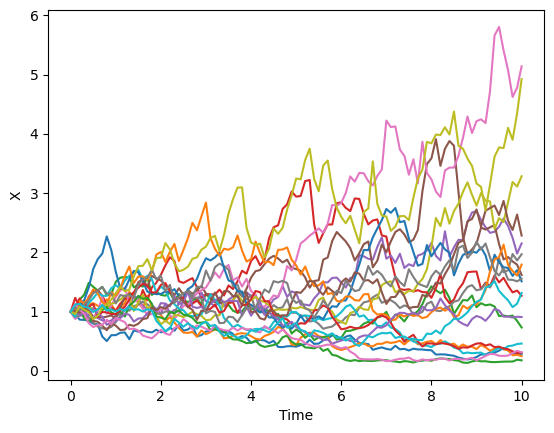

In [52]:
# time grid
time = np.linspace(0, T, N + 1)

# pre-allocate array
X = np.zeros((num_paths, N+1))

# Initial value for every path
X[:, 0] = X0

# simulation of paths
for i in range(num_paths):
    for t in range(1,N+1): 
        dW = np.sqrt(dt) * np.random.normal(0, 1)
        X[i, t] = X[i,t-1] + r*X[i,t-1]*dt + sigma_scalar*X[i,t-1]*dW

# Plot the result
plt.plot(time, X[:20].T)
plt.xlabel("Time")
plt.ylabel("X")
plt.show()


In [53]:
print("X min:", X.min())
print("X max:", X.max())
print("X final min:", X[:, -1].min())
print("X final max:", X[:, -1].max())

print(X[:, -1])

X min: 0.030378449866616183
X max: 25.410159524799926
X final min: 0.030378449866616183
X final max: 18.238382279053145
[ 0.2840519   0.24806721  0.73265112  1.26888701  2.15151063  1.61871312
  5.13975113  1.96842474  3.28535723  0.46198925  1.51160499  1.79446623
  0.17847996  0.309365    0.90922116  2.2846731   0.31334381  1.55708596
  4.92438903  1.31512086  0.99872747  7.72747531  1.49173223  6.44751309
  1.28986342  1.07025468  1.55373023  0.31880083  3.29591289  0.31398504
  4.17355523  0.21994363  1.75759239  0.71139592  4.08444932  0.78489716
 10.26637599  1.85287202  0.33956151  1.22494894  0.69976048  1.18619575
  1.1904345   0.15007213  0.32437272  0.82159572  1.22227641  0.37842129
  1.23571598  3.88141227  0.85949241  0.9302738   1.01834582  2.16353683
  0.3615328   0.67886844  0.34936128  1.89749695  0.62677653  0.25879473
  0.19666143  0.23094273  1.02429325  0.57327176  0.31582473  0.24302544
  1.1078463   0.4012686   0.82114621  0.83086788  0.52174461  0.45134992
  3.

### Implementing the Neural SDE

Here we will define the neural networks $\mu_\theta$ and $\sigma_\theta$. To do so we will use two classes *DriftNN* and *DiffusionNN*.

Here it is important to state that we have the system
$$1 \rightarrow 32 \rightarrow 32 \rightarrow 1,$$
that is because we definied the number of hidden layers as $32$ and the number of units per layer as $2$, this concludes in using $32$ twice. In the Section Paramters we can change the two parameters and therefore change the system, however for our use this is enough.


In [54]:
class DriftNN(nn.Module):
    # class for Drift as Neuronal Network
    def __init__(self,hidden_dim): 
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(1, hidden_dim), 
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, 1)
        )

    def forward(self, x):
        return self.net(x)

# VL Foundations of ML Grenoble

In [55]:
class DiffusionNN(nn.Module):
    # class for Diffusion as Neuronal Network
    def __init__(self,hidden_dim): 
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(1, hidden_dim), 
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, 1)
        )

    def forward(self, x):
        return torch.nn.functional.softplus(self.net(x))

For the neural network of the diffusion the forward function is normally defined differently because we want to achieve only positive outputs, which is done through the softplus function
$$ \mathbb{R}\rightarrow\mathbb{R}^+\cup \{0\},\qquad\ln(1 + e^x).$$


### Calibration

Training

Now we need to train the neural networks in order to find drift and diffusion that fit the model.

In [56]:
# save paths for later use
X_t = X[:, :-1].reshape(-1, 1) # reshaped to fit the neural network later on
X_next = X[:, 1:].reshape(-1, 1)
# convert them to tensors
X_t = torch.from_numpy(X_t).float()
X_next = torch.from_numpy(X_next).float()

# DataLoader - to set batch size, to decrease running time
# https://docs.pytorch.org/tutorials/beginner/basics/data_tutorial.html

dataset = TensorDataset(X_t, X_next)

train_loader = DataLoader(dataset,batch_size=batch_size,shuffle=True)

In [57]:
# loss history to save later
loss_history = []

# to define hidden_dim, otherwise wrong input later
drift_nn = DriftNN(hidden_dim)
diffusion_nn = DiffusionNN(hidden_dim)

# Normalisation scale for the network input/output.
# This improves numerical conditioning without changing the learned functions.
x_scale = float(np.quantile(X_t.numpy(), 0.99))
x_scale = max(x_scale, 1.0)

# defining optimizer
optimizer = optim.Adam(list(drift_nn.parameters()) +list(diffusion_nn.parameters()),lr = learning_rate) # https://github.com/am1tyadav/Neural-Network-from-Scratch-Python

for epoch in range (num_runs):

    epoch_loss = 0.0

    for X_batch, X_next_batch in train_loader:

        x_in = X_batch / x_scale

        # Set drift and diffusion
        mu = x_scale * drift_nn(x_in)
        sigma = x_scale * diffusion_nn(x_in)

        # calculate mean and variance
        mean = X_batch + mu * dt
        variance = sigma.pow(2) * dt
        variance = torch.clamp(variance, min=1e-8)

        # Negative Log-Likelihood
        loss = 0.5 * ( torch.log(2 * torch.pi * variance) + (X_next_batch - mean)**2 / variance).mean() # genauer in Latex herleiten!!! + Grund dass Betrag von Fehler nicht kleiner werden muss

        # Backpropagation
        optimizer.zero_grad() 
        loss.backward() # training error
        optimizer.step()

        epoch_loss += loss.item()

    # Average loss over all batches
    epoch_loss /= len(train_loader)

    loss_history.append(epoch_loss)


    print(
        f"Epoch {epoch}/{num_runs}, "
        f"Loss = {epoch_loss:.6f}"
        )



Epoch 0/20, Loss = -0.404119
Epoch 1/20, Loss = -0.900154
Epoch 2/20, Loss = -0.917304
Epoch 3/20, Loss = -0.925285
Epoch 4/20, Loss = -0.929137
Epoch 5/20, Loss = -0.931180
Epoch 6/20, Loss = -0.932146
Epoch 7/20, Loss = -0.932779
Epoch 8/20, Loss = -0.933984
Epoch 9/20, Loss = -0.934211
Epoch 10/20, Loss = -0.934159
Epoch 11/20, Loss = -0.935042
Epoch 12/20, Loss = -0.935299
Epoch 13/20, Loss = -0.934721
Epoch 14/20, Loss = -0.935383
Epoch 15/20, Loss = -0.935952
Epoch 16/20, Loss = -0.935968
Epoch 17/20, Loss = -0.935756
Epoch 18/20, Loss = -0.936046
Epoch 19/20, Loss = -0.935715


Now we plot the result to see if the loss is getting smaller.

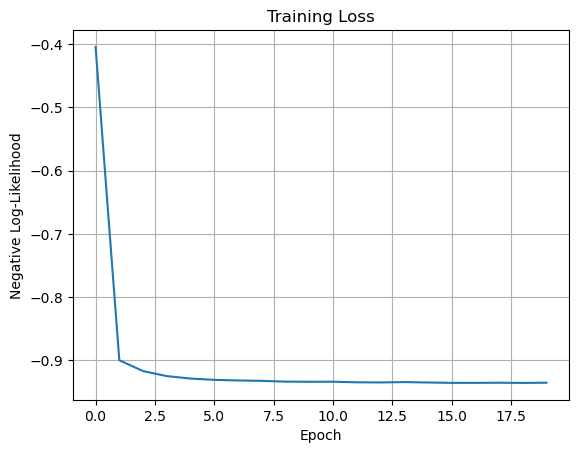

In [58]:
plt.plot(loss_history)
plt.xlabel("Epoch")
plt.ylabel("Negative Log-Likelihood")
plt.title("Training Loss")
plt.grid()
plt.show()

However it is even better to know how good our trained $\mu$ and trained $\sigma$ approximate the functions for the drift and diffusion of the Black-Scholes that are
$$ \mu(x) = r\,x \quad\text{and} \quad\sigma (x) = \sigma\,x.$$
Therefore, we try to verify that
$$ \mu_\theta (x) \sim r\,x \quad \text{and} \quad \sigma_\theta (x) \sim \sigma\,x. $$

In [59]:
# Evaluate only where the simulated data actually has substantial support.
# Extreme outliers can otherwise dominate the visual comparison.
X_all = train_loader.dataset.tensors[0]
x_low = torch.quantile(X_all, 0.01).item()
x_high = torch.quantile(X_all, 0.99).item()
x_plot = torch.linspace(x_low, x_high, 300).reshape(-1, 1)

# evaluating drift and diffusion
drift_nn.eval()
diffusion_nn.eval()


with torch.no_grad(): # because it is only evaluated not trained
    x_in = x_plot / x_scale
    mu_trained = x_scale * drift_nn(x_in)
    sigma_trained = x_scale * diffusion_nn(x_in)

# calculating true value
mu_true = r*x_plot
sigma_true = sigma_scalar*x_plot

print(X_all.shape)
print(x_plot.shape)
print(mu_trained.shape)


torch.Size([100000, 1])
torch.Size([300, 1])
torch.Size([300, 1])


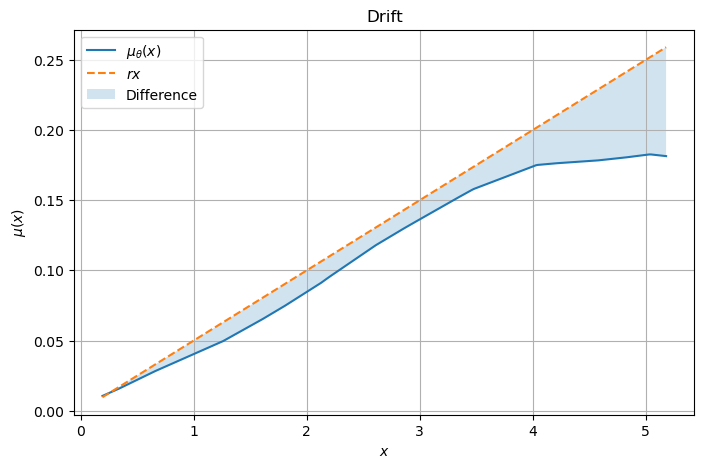

In [60]:
# plotting drift
plt.figure(figsize=(8, 5))

plt.plot(
    x_plot.numpy(),
    mu_trained.numpy(),
    label=r'$\mu_\theta(x)$'
)

plt.plot(
    x_plot.numpy(),
    mu_true.numpy(),
    '--',
    label=r'$rx$'
)

plt.fill_between(
    x_plot.squeeze().numpy(),
    mu_trained.squeeze().numpy(),
    mu_true.squeeze().numpy(),
    alpha=0.2,
    label='Difference'
)

plt.xlabel(r'$x$')
plt.ylabel(r'$\mu(x)$')
plt.title('Drift')
plt.legend()
plt.grid()
plt.show()

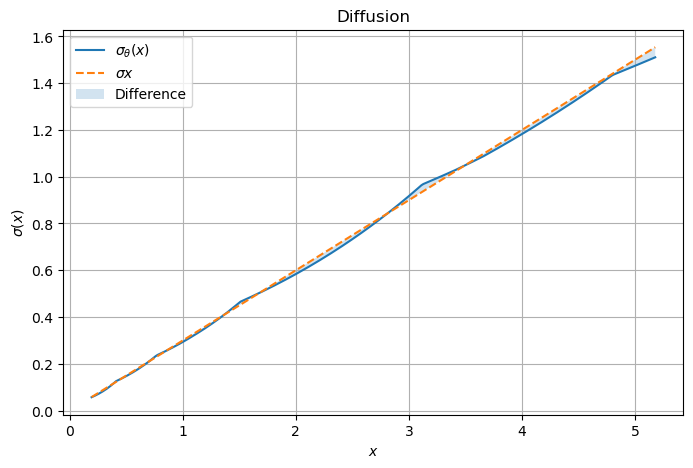

In [61]:
# plotting diffusion
plt.figure(figsize=(8, 5))

plt.plot(
    x_plot.numpy(),
    sigma_trained.numpy(),
    label=r'$\sigma_\theta(x)$'
)

plt.plot(
    x_plot.numpy(),
    sigma_true.numpy(),
    '--',
    label=r'$\sigma x$'
)

plt.fill_between(
    x_plot.squeeze().numpy(),
    sigma_trained.squeeze().numpy(),
    sigma_true.squeeze().numpy(),
    alpha=0.2,
    label='Difference'
)

plt.xlabel(r'$x$')
plt.ylabel(r'$\sigma(x)$')
plt.title('Diffusion')
plt.legend()
plt.grid()
plt.show()

Both of these plots show that the learned parameters are approximating the real values already quite good.

Loss

Now we want to calculate how much loss we had while calculating the drift and later the diffusion. For this we use the loss function
$$ L_{\mu}(\theta)=\sum_{j=1}^N (\mu_i^{trained}(\theta)-\mu_i^{true})^2 $$
and
$$ L_{\sigma}(\theta)=\sum_{j=1}^N (\sigma_i^{trained}(\theta)-\sigma_i^{true})^2 $$

In [62]:
# Loss of drift
mu_loss = ((mu_trained - mu_true)**2).mean()

print("Drift Loss:", mu_loss.item())

Drift Loss: 0.000816435378510505


In [63]:
# Loss of diffusion
sigma_loss = ((sigma_trained - sigma_true)**2).mean()

print("Diffusion Loss:", sigma_loss.item())

Diffusion Loss: 0.00021300352818798274


Here we can see that the learned drift and diffusion are on average already very close to the true value.

Optimization

In my thesis I described the optimization step through the stochastic gradient descent method, first for drift then for diffusion. This is done by minimizing the gradient of the loss
$$\frac{1}{m}
    \nabla_\theta
    \sum_{i=1}^{m}
    L_{\mu}\left(\theta\right),$$
    
respectively
$$\frac{1}{m}
    \nabla_\theta
    \sum_{i=1}^{m}
    L_{\sigma}\left(\theta\right)$$
and updating the paramters accordingly.


However this is already done in the optimizer step of the training.